# 6. Unknown and changing volatility

Every hedge so far knew the volatility of the market it was trained on. In practice volatility is not observed: it has to be estimated, and it changes during the life of the option. This part takes the multi-contract hedge of part 5 and asks three questions:

1. What happens when the true volatility differs from the training one?
2. Does it help to train across volatility regimes and give the network the volatility as an input?
3. Does that still work when the volatility is estimated from past returns, and when it moves during the hedge?

The benchmark is the no-trade band, given exactly the same volatility information as the network.

In [1]:
from itertools import product

import numpy as np
import torch
import matplotlib.pyplot as plt

from deephedge import simulate
from deephedge.benchmarks import band_holdings, delta_holdings, time_to_maturity
from deephedge.losses import avar, grouped_avar_objective, hedging_loss
from deephedge.models import PositionHedge
from deephedge.plotting import COLORS, MUTED, style, save
from deephedge.stats import grouped_avar_ratio_interval
from deephedge.train import fit

N, eps, alpha = 30, 0.01, 0.9
C_GRID = np.round(np.arange(0.0, 0.401, 0.025), 3)
CONTRACTS = list(product([0.90, 1.00, 1.10], [0.125, 0.50], [1, -1]))           # training contracts of part 5
TEST_CONTRACTS = [(0.95, 0.25, 1), (0.95, 0.25, -1), (1.05, 0.25, 1), (1.05, 0.25, -1)]
name = lambda c: f"{'call' if c[2] == 1 else 'put'} K={c[0]:.2f}"


def features(S, info, vol=None):
    # inputs of part 5 on their fixed scales, plus the log volatility around 35% if given
    tau = time_to_maturity(info["T"], N)
    z = [torch.log(S[:, :-1] / info["K"][:, None]) / 0.2, tau / 0.5, info["kind"][:, None].expand_as(tau)]
    if vol is not None:
        z.append(torch.log(torch.as_tensor(vol, dtype=torch.float64).expand_as(tau) / 0.35) / 0.7)
    return torch.stack(z, dim=-1).float()


def loss(H, S, info):
    return hedging_loss(H, S, K=info["K"], kind=info["kind"], eps=eps)[0]


def deep_loss(model, S, info, vol=None):
    with torch.no_grad():
        return loss(model(S.float(), features(S, info, vol)).double(), S, info)


def band_loss(S, info, c, vol):
    return loss(band_holdings(S, eps, c, vol, info["K"], info["T"], info["kind"]), S, info)


def mean_group_avar(X, groups):
    return np.mean([avar(X[groups == g], alpha) for g in groups.unique()])


def paired_interval(X_ref, X_new, groups):
    # paths resampled within each contract, the two strategies with the same indices
    return grouped_avar_ratio_interval(X_ref, X_new, groups)

## 6.1 The part 5 hedge when the volatility is wrong

The multi-contract network of part 5 was trained at $\sigma = 35\%$. We test it on its four unseen contracts at four true volatilities, against two bands: one that also assumes 35%, and one that knows the true volatility.

In [2]:
S_p5, info_p5 = simulate.contract_paths(CONTRACTS, 5000, seed=1301)                 # part 5 training data
single = PositionHedge(S_p5.float(), features(S_p5, info_p5), n_thresholds=len(CONTRACTS), standardise=False)
single.load_state_dict(torch.load("../results/models/part5_multi_contract.pt"))
single.eval()
c_single = {}                                       # band widths at sigma = 35%, tuned as in part 5
S_v, info_v = simulate.contract_paths(CONTRACTS, 1000, seed=1302)
for kind in [1, -1]:
    m = info_v["kind"] == kind
    sub = {k: v[m] for k, v in info_v.items()}
    c_single[kind] = C_GRID[int(np.argmin([mean_group_avar(band_loss(S_v[m], sub, c, 0.35), sub["group"]) for c in C_GRID]))]
print("band widths at sigma = 35%:", c_single)

print(f"\n{'true vol':>9s}{'':4s}{'vs band, 35% assumed':>22s}{'vs band, true vol':>19s}")
for i, vol in enumerate([0.25, 0.35, 0.50, 0.70]):
    S, info = simulate.contract_paths([c + (vol,) for c in TEST_CONTRACTS], 6000, seed=1400 + i)
    c = torch.where(info["kind"] == 1, c_single[1], c_single[-1])
    X_deep = deep_loss(single, S, info)
    g_fixed = mean_group_avar(X_deep, info["group"]) / mean_group_avar(band_loss(S, info, c, 0.35), info["group"]) - 1
    g_true = mean_group_avar(X_deep, info["group"]) / mean_group_avar(band_loss(S, info, c, info["sigma"]), info["group"]) - 1
    print(f"{vol:9.0%}{'':4s}{g_fixed:+22.1%}{g_true:+19.1%}")

band widths at sigma = 35%: {1: np.float64(0.125), -1: np.float64(0.15)}

 true vol      vs band, 35% assumed  vs band, true vol
      25%                     +4.1%              +1.6%


      35%                     +0.2%              +0.2%
      50%                     -4.1%              +6.9%


      70%                     -6.3%             +18.2%


At the training volatility the network is level with the band (+0.2%), as in part 5. When the true volatility differs, the comparison depends entirely on what the band is told. Against a band that also assumes 35%, the network does better when volatility is higher (−4.1% at 50%, −6.3% at 70%) and worse when it is lower. Against a band that knows the true volatility it loses everywhere, by up to 18% at 70%. A network trained in one volatility regime has learned that regime, nothing more.

## 6.2 Training across volatility regimes

The 12 contracts of part 5 at four volatilities, 25%, 35%, 50% and 70%: 48 groups of 2,000 paths, one AVaR threshold each. The **aware** network receives the volatility as a fifth input (its logarithm). To isolate the value of that input, a **blind** network is trained on exactly the same paths without it. Checkpoints are selected on validation paths.

Test: the four unseen contracts at three volatilities that were never trained on, 30%, 42.5% and 60%. Here the volatility is known. The band also knows it, and its width is tuned on validation paths at each training volatility, then interpolated.

In [3]:
TRAIN_VOLS = [0.25, 0.35, 0.50, 0.70]
TEST_VOLS = [0.30, 0.425, 0.60]
VOL_CONTRACTS = [c + (v,) for c in CONTRACTS for v in TRAIN_VOLS]
S_tr, info_tr = simulate.contract_paths(VOL_CONTRACTS, 2000, seed=14011)
S_va, info_va = simulate.contract_paths(VOL_CONTRACTS, 400, seed=14012)


def train_vol(seed, aware=True):
    vol_tr = info_tr["sigma"][:, None] if aware else None
    vol_va = info_va["sigma"][:, None] if aware else None
    Z = features(S_tr, info_tr, vol_tr)
    torch.manual_seed(seed)
    model = PositionHedge(S_tr.float(), Z, n_thresholds=len(VOL_CONTRACTS), standardise=False)
    objective = lambda m, s, z, k, knd, g: grouped_avar_objective(hedging_loss(m(s, z), s, K=k, kind=knd, eps=eps)[0],
                                                                  m.w, g, alpha)
    validate = lambda m: mean_group_avar(deep_loss(m, S_va, info_va, vol_va), info_va["group"])
    tensors = (S_tr.float(), Z, info_tr["K"].float(), info_tr["kind"].float(), info_tr["group"])
    return fit(model, tensors, objective, batch_size=2400, validate=validate, every=1, progress=False)[0]


aware = train_vol(seed=1404)
blind = train_vol(seed=1404, aware=False)

# band width by option type and training volatility, tuned on validation, interpolated in between
c_table = {}
for kind in [1, -1]:
    row = []
    for vol in TRAIN_VOLS:
        m = (info_va["kind"] == kind) & (info_va["sigma"] == vol)
        sub = {k: v[m] for k, v in info_va.items()}
        row.append(C_GRID[int(np.argmin([mean_group_avar(band_loss(S_va[m], sub, c, vol), sub["group"]) for c in C_GRID]))])
    c_table[kind] = row
print("band widths by training volatility:", {("call" if k == 1 else "put"): v for k, v in c_table.items()})


def band_width(info, vol):
    # interpolated band factor for each path, from the volatility the band believes
    v = torch.as_tensor(vol, dtype=torch.float64).reshape(len(info["K"]), -1)[:, 0].numpy()
    calls = np.interp(v, TRAIN_VOLS, c_table[1])
    puts = np.interp(v, TRAIN_VOLS, c_table[-1])
    return torch.tensor(np.where(info["kind"].numpy() == 1, calls, puts))


print(f"\n{'test vol':>9s}{'':3s}{'aware vs band':>15s}{'95% interval':>18s}{'blind vs band':>15s}{'aware vs blind':>16s}")
for i, vol in enumerate(TEST_VOLS):
    S, info = simulate.contract_paths([c + (vol,) for c in TEST_CONTRACTS], 6000, seed=1500 + i)
    X_band = band_loss(S, info, band_width(info, info["sigma"]), info["sigma"])
    X_aware = deep_loss(aware, S, info, info["sigma"][:, None])
    X_blind = deep_loss(blind, S, info)
    a = {k: mean_group_avar(x, info["group"]) for k, x in [("band", X_band), ("aware", X_aware), ("blind", X_blind)]}
    lo, hi = paired_interval(X_band, X_aware, info["group"])
    interval = f"[{lo:+.1%}, {hi:+.1%}]"
    print(f"{vol:9.1%}{'':3s}{a['aware'] / a['band'] - 1:+15.1%}{interval:>18s}{a['blind'] / a['band'] - 1:+15.1%}"
          f"{a['aware'] / a['blind'] - 1:+16.1%}")

band widths by training volatility: {'call': [np.float64(0.15), np.float64(0.15), np.float64(0.15), np.float64(0.125)], 'put': [np.float64(0.125), np.float64(0.15), np.float64(0.15), np.float64(0.15)]}

 test vol     aware vs band      95% interval  blind vs band  aware vs blind


    30.0%             +0.3%    [-0.1%, +0.8%]          +4.3%           -3.8%


    42.5%             +1.1%    [+0.7%, +1.5%]          +1.2%           -0.1%


    60.0%             +2.2%    [+1.7%, +2.6%]          +4.3%           -2.1%


Training across regimes with the volatility as an input clearly helps: the aware network is 2% to 4% better than the blind one at 30% and 60%, and it no longer breaks down when volatility changes. But it does not beat the band that knows the volatility: it is level at 30% and 1% to 2% worse at 42.5% and 60%, with intervals above zero. Interpolating between volatility regimes is harder for the network than for a formula in which volatility enters explicitly.

## 6.3 Estimated and moving volatility

Now nobody knows the volatility. Each path comes with 120 earlier observations, and before every trade the volatility is estimated from the last 20 or 120 returns only; network and band receive the same estimate. Two markets:

- **constant volatility**, which must be estimated;
- **stochastic volatility**: the log-volatility mean-reverts to the base level (speed 8 per year, volatility of volatility 0.75), and its shocks are correlated with price shocks (correlation $-0.4$), so volatility rises when prices fall.

The aware network is the one of section 6.2, unchanged.

In [4]:
def estimated_run(eta, window, base_vol, seed):
    S, info, R = simulate.sv_paths([c + (base_vol,) for c in TEST_CONTRACTS], 6000, seed=seed, eta=eta)
    vol_hat = simulate.realised_vol(R, info["T"], window)
    X_band = band_loss(S, info, band_width(info, vol_hat), vol_hat)
    X_deep = deep_loss(aware, S, info, vol_hat)
    return X_band, X_deep, info


print(f"{'market':>12s}{'window':>8s}" + "".join(f"{f'vol {v:.1%}':>22s}" for v in TEST_VOLS))
print(f"{'':20s}" + "".join(f"{'deep vs band [95%]':>22s}" for _ in TEST_VOLS))
sv_results = {}
for eta, market in [(0.0, "constant"), (0.75, "stochastic")]:
    for window in [20, 120]:
        row = []
        for i, vol in enumerate(TEST_VOLS):
            X_band, X_deep, info = estimated_run(eta, window, vol, seed=1600 + 10 * i)
            g = mean_group_avar(X_deep, info["group"]) / mean_group_avar(X_band, info["group"]) - 1
            lo, hi = paired_interval(X_band, X_deep, info["group"])
            sv_results[(market, window, vol)] = (X_band, X_deep, info)
            row.append(f"{g:+.1%} [{lo:+.1%}, {hi:+.1%}]")
        print(f"{market:>12s}{window:8d}" + "".join(f"{r:>22s}" for r in row))

      market  window             vol 30.0%             vol 42.5%             vol 60.0%
                        deep vs band [95%]    deep vs band [95%]    deep vs band [95%]


    constant      20  +0.9% [+0.5%, +1.4%]  +1.7% [+1.3%, +2.1%]  +2.6% [+2.2%, +3.0%]


    constant     120  +1.0% [+0.4%, +1.4%]  +1.5% [+1.0%, +1.9%]  +2.3% [+1.8%, +2.7%]


  stochastic      20  +1.3% [+0.9%, +1.8%]  +2.2% [+1.7%, +2.6%]  +2.6% [+2.2%, +3.1%]


  stochastic     120  +0.5% [-0.1%, +1.0%]  +1.2% [+0.7%, +1.7%]  +1.7% [+1.3%, +2.2%]


With estimated volatility the network stays 0.5% to 2.6% behind the band, in both markets and with both windows; only one interval (stochastic volatility, 120 returns, base 30%) includes zero. Under stochastic volatility the noisier 20-return estimate widens the gap. When the volatility input is uncertain, the band, whose dependence on volatility is fixed by the Black–Scholes formulas, is the more robust of the two.

## 6.4 Training seeds

The last result rests on one trained network. Two more aware networks, trained from different initialisations on the same paths, are evaluated on the same stochastic-volatility test paths with the 120-step estimate.

In [5]:
seed_models = {1404: aware, 1405: train_vol(seed=1405), 1406: train_vol(seed=1406)}
summary = []
print(f"{'base vol':>9s}" + "".join(f"{f'seed {s}':>12s}" for s in seed_models) + f"{'mean':>10s}{'contracts won':>15s}")
for vol in TEST_VOLS:
    S, info, R = simulate.sv_paths([c + (vol,) for c in TEST_CONTRACTS], 6000, seed=1600 + 10 * TEST_VOLS.index(vol), eta=0.75)
    vol_hat = simulate.realised_vol(R, info["T"], 120)
    X_band = band_loss(S, info, band_width(info, vol_hat), vol_hat)
    gains, wins = [], 0
    for seed, model in seed_models.items():
        X_deep = deep_loss(model, S, info, vol_hat)
        gains.append(mean_group_avar(X_deep, info["group"]) / mean_group_avar(X_band, info["group"]) - 1)
        wins += sum(avar(X_deep[info["group"] == g], alpha) < avar(X_band[info["group"] == g], alpha) for g in range(4))
    summary.append(dict(vol=vol, gains=gains, mean=np.mean(gains), wins=wins))
    print(f"{vol:9.1%}" + "".join(f"{g:+12.2%}" for g in gains) + f"{np.mean(gains):+10.2%}{f'{wins} of 12':>15s}")

for seed, model in seed_models.items():
    torch.save(model.state_dict(), f"../results/models/part6_vol_aware_seed{seed}.pt")

 base vol   seed 1404   seed 1405   seed 1406      mean  contracts won


    30.0%      +0.46%      +0.04%      +0.91%    +0.47%        4 of 12


    42.5%      +1.20%      +0.97%      +1.59%    +1.25%        0 of 12


    60.0%      +1.73%      +1.82%      +1.68%    +1.74%        0 of 12


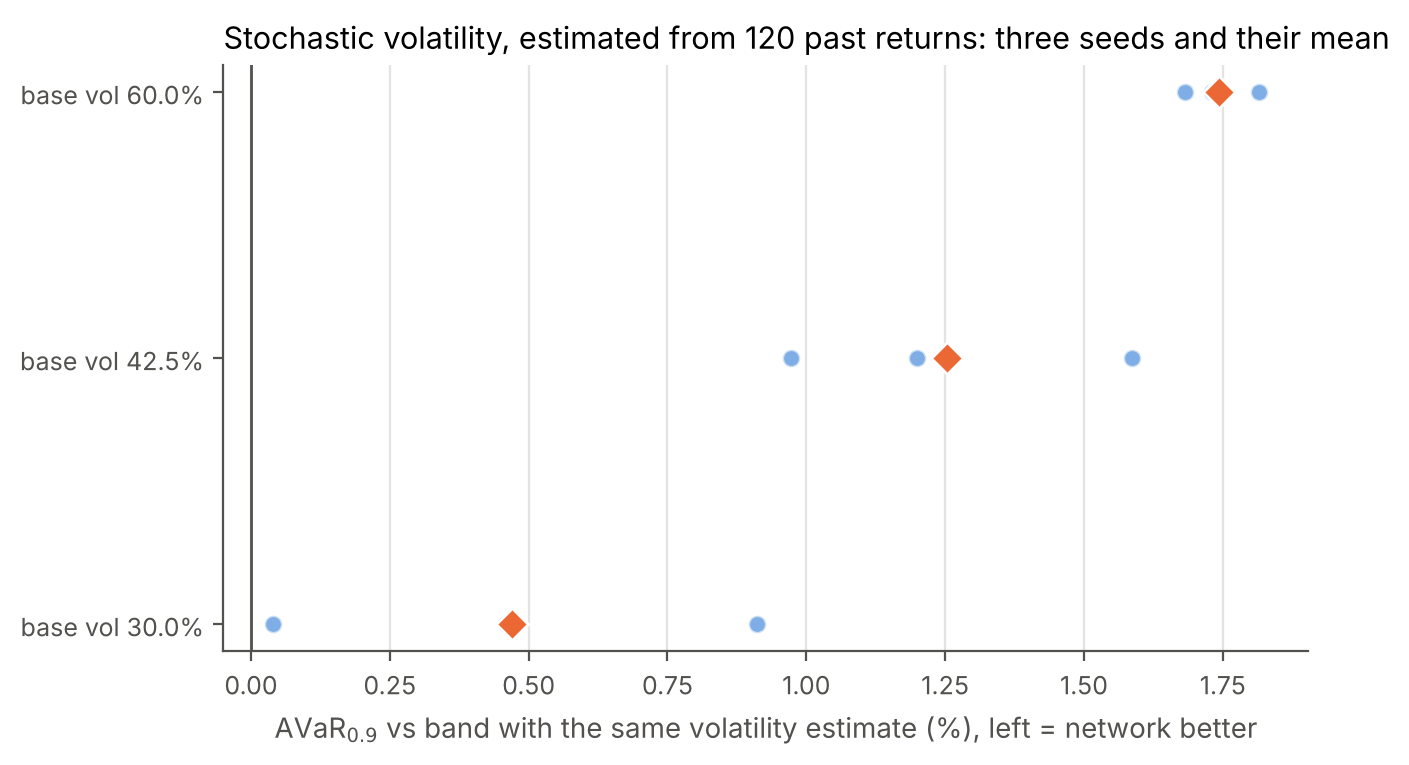

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for i, s in enumerate(summary):
    ax.scatter([100 * g for g in s["gains"]], [i] * 3, color=COLORS["deep"], s=40, alpha=0.6, edgecolor="white")
    ax.plot(100 * s["mean"], i, "D", color=COLORS["band"], ms=8, mec="white")
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(range(len(summary)), [f"base vol {s['vol']:.1%}" for s in summary])
ax.set_xlabel("AVaR$_{0.9}$ vs band with the same volatility estimate (%), left = network better")
ax.set_title("Stochastic volatility, estimated from 120 past returns: three seeds and their mean", loc="left", fontsize=11)
style(ax, grid="x")
save(fig, "part6_seeds")
plt.show()

The three seeds agree: under stochastic volatility with a 120-return estimate the network is 0.5% behind the band at 30%, 1.3% at 42.5% and 1.7% at 60%, and it wins only 4 of the 36 contract comparisons.

**What this part shows.** The gains of parts 3 to 5 were obtained with a known volatility. Once volatility has to be estimated and can move, a calibrated no-trade band that uses the same estimate is at least as good as the network in this setting. Training across regimes with volatility as an input is necessary (without it the network breaks down when volatility changes) but not sufficient to beat the band. Whether training directly on estimated volatility, or on a richer view of past returns, closes the gap is left open.